<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/opencv%2Bdt/Sinhala_Baseline_OpenCV_DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sinhala Handwriting — Baseline Deviation Detection
## Experiment: OpenCV + Decision Tree

This notebook classifies handwritten Sinhala lines as **correct** (written on the guide line) or **wrong** (baseline deviation) using **OpenCV feature extraction + a Decision Tree classifier**.

| Stage | What happens |
|---|---|
| 1. Load dataset → split into train / validation / test (70/15/15) | stratified, fixed random seed (42) |
| 2. OpenCV preprocessing | grayscale → resize → CLAHE → denoise → deskew |
| 3. OpenCV feature extraction | guide line, word gaps, drift, waviness (22 features) |
| 4. Train Decision Tree | hyperparameters tuned with cross-validation on the training set |
| 5. Evaluate | all metrics, confusion matrix, ROC / PR, cross-validation, learning curve |
| 6. Explain | the learned if/else rules, tree diagram, feature importance |
| 7. Save & download | model (`.joblib`), metrics, preprocessed images |

> The split uses a fixed seed, so other experiment notebooks (e.g. OpenCV + SVM) run on **exactly the same train/val/test images** and can be compared fairly.

**Dataset structure expected**
```
baseline dataset/
├── correct/   (images)
└── wrong/     (images)
```

> **Tip:** Runtime → *Run all*. The only cell you must edit is **Step 2 (Configuration)**.

## Step 1 — Import libraries

In [ ]:
import os, re, glob, json, time, shutil, zipfile, random, warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import joblib

from sklearn.model_selection import (train_test_split, GroupShuffleSplit, StratifiedKFold,
                                     GridSearchCV, cross_validate, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             cohen_kappa_score, log_loss, brier_score_loss, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")
print("OpenCV       :", cv2.__version__)
import sklearn; print("scikit-learn :", sklearn.__version__)
print("XGBoost      :", HAS_XGB)

OpenCV       : 5.0.0
scikit-learn : 1.6.1
XGBoost      : True


## Step 2 — Configuration


In [ ]:
DATA_SOURCE        = "drive"                                   # "drive" or "upload_zip"
DRIVE_DATASET_PATH = "/content/drive/MyDrive/dataset"  # this folder or any parent of correct/ and wrong/

CLASS_NAMES    = ["correct", "wrong"]   # label 0 = correct, label 1 = wrong (baseline deviation)
POSITIVE_CLASS = 1                      # metrics like precision/recall are reported for "wrong"

TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.70, 0.15, 0.15
GROUP_PATTERN = None                    # e.g. r"^([A-Za-z]*\d+)_"  for student-wise split

TARGET_WIDTH = 1600                     # every image is resized to this width (aspect ratio kept)
WORK_DIR     = Path("/content/work")    # preprocessed images, features, models, plots go here
SAVE_TO_DRIVE_DIR = "/content/drive/MyDrive/baseline_DT_results"   # results copied here at the end (drive mode)

WORK_DIR.mkdir(parents=True, exist_ok=True)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

## Step 3 — Load the dataset

Mounted at /content/drive
Dataset folder: /content/drive/MyDrive/dataset/Baseline dataset


Checking images:   0%|          | 0/298 [00:00<?, ?it/s]


Total images: 298
class_name
correct    205
wrong       93


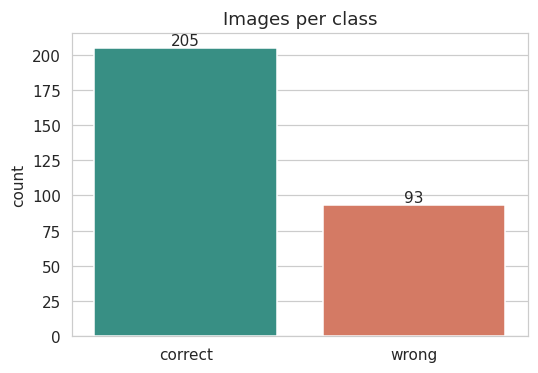

In [ ]:
if DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATASET_ROOT = Path(DRIVE_DATASET_PATH)
elif DATA_SOURCE == "upload_zip":
    from google.colab import files
    uploaded = files.upload()                      # choose your dataset .zip
    zip_name = next(iter(uploaded))
    extract_to = Path("/content/dataset")
    shutil.rmtree(extract_to, ignore_errors=True)
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(extract_to)
    DATASET_ROOT = extract_to
else:
    DATASET_ROOT = Path(DRIVE_DATASET_PATH)       # local path (when not running on Colab)


def find_class_root(root, class_names):
    # search for the folder that directly contains every class folder (case-insensitive)
    for d in [root] + sorted(p for p in root.rglob("*") if p.is_dir()):
        subs = {p.name.lower(): p for p in d.iterdir() if p.is_dir()}
        if all(c.lower() in subs for c in class_names):
            return d, {c: subs[c.lower()] for c in class_names}
    raise FileNotFoundError(f"Could not find folders {class_names} inside {root}")


DATASET_ROOT, CLASS_DIRS = find_class_root(DATASET_ROOT, CLASS_NAMES)
print("Dataset folder:", DATASET_ROOT)

records = []
for label, cname in enumerate(CLASS_NAMES):
    for p in sorted(CLASS_DIRS[cname].rglob("*")):
        if p.suffix.lower() in IMG_EXTS and not p.name.startswith("."):
            records.append({"path": str(p), "filename": p.name, "class_name": cname, "label": label})
df = pd.DataFrame(records)

# drop unreadable images
ok = [cv2.imread(p, cv2.IMREAD_REDUCED_GRAYSCALE_8) is not None for p in tqdm(df.path, desc="Checking images")]
bad = df[~np.array(ok)]
if len(bad):
    print(f"⚠️ {len(bad)} unreadable files skipped:", bad.filename.tolist()[:10])
df = df[np.array(ok)].reset_index(drop=True)

print(f"\nTotal images: {len(df)}")
print(df.class_name.value_counts().to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="class_name", order=CLASS_NAMES, palette=["#2a9d8f", "#e76f51"], ax=ax)
for c in ax.containers: ax.bar_label(c)
ax.set_title("Images per class"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

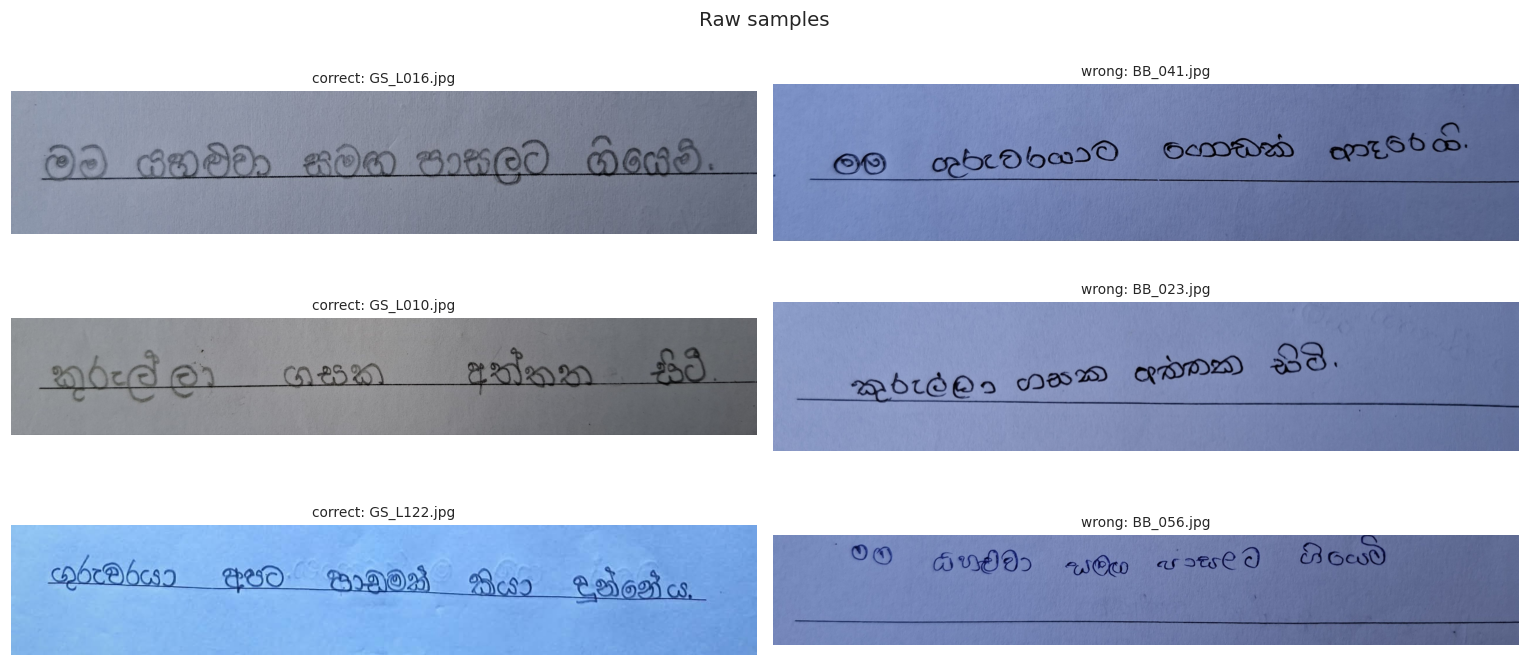

In [ ]:
# a few raw samples from each class
n_show = 3
fig, axes = plt.subplots(n_show, 2, figsize=(14, 2.2 * n_show))
for col, cname in enumerate(CLASS_NAMES):
    sub = df[df.class_name == cname].sample(min(n_show, (df.class_name == cname).sum()), random_state=SEED)
    for row in range(n_show):
        ax = axes[row, col]; ax.axis("off")
        if row < len(sub):
            img = cv2.cvtColor(cv2.imread(sub.iloc[row].path), cv2.COLOR_BGR2RGB)
            ax.imshow(img); ax.set_title(f"{cname}: {sub.iloc[row].filename}", fontsize=9)
plt.suptitle("Raw samples", fontsize=13); plt.tight_layout(); plt.show()

## Step 4 — Split into train / validation / test

Stratified split (70 % / 15 % / 15 %) keeps the correct/wrong ratio the same in every split. The split is done **before** any training so the test set stays completely unseen.

In [ ]:
def split_dataset(df):
    if GROUP_PATTERN:
        groups = df.filename.apply(lambda f: (re.search(GROUP_PATTERN, f) or [None, f])[1])
        print(f"Student-wise split using {groups.nunique()} groups")
        gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
        trval_idx, test_idx = next(gss.split(df, df.label, groups))
        trval = df.iloc[trval_idx]
        gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE / (TRAIN_SIZE + VAL_SIZE), random_state=SEED)
        tr_idx, val_idx = next(gss2.split(trval, trval.label, groups.iloc[trval_idx]))
        return trval.iloc[tr_idx], trval.iloc[val_idx], df.iloc[test_idx]
    trval, test = train_test_split(df, test_size=TEST_SIZE, stratify=df.label, random_state=SEED)
    train, val = train_test_split(trval, test_size=VAL_SIZE / (TRAIN_SIZE + VAL_SIZE),
                                  stratify=trval.label, random_state=SEED)
    return train, val, test


train_df, val_df, test_df = split_dataset(df)
df["split"] = ""
df.loc[train_df.index, "split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"

split_table = pd.crosstab(df.split, df.class_name).reindex(["train", "val", "test"])[CLASS_NAMES]
split_table["total"] = split_table.sum(axis=1)
split_table["% of data"] = (100 * split_table.total / len(df)).round(1)
display(split_table)
df.to_csv(WORK_DIR / "dataset_split.csv", index=False)

class_name,correct,wrong,total,% of data
split,,,,
train,143,65,208,69.8
val,31,14,45,15.1
test,31,14,45,15.1


## Step 5 — Preprocessing (grayscale, resize, lighting fix, denoise, deskew)

| Step | Why |
|---|---|
| **Grayscale** | Colour (blue paper, pen colour) is not needed to judge the baseline |
| **Resize to a fixed width** (aspect ratio kept) | Same scale for every image; *never* squash to a square — it distorts the drift |
| **CLAHE** | Fixes uneven phone-camera lighting (e.g. darker on the left) |
| **Non-local means denoise** | Removes paper texture / camera noise |
| **Adaptive threshold** | Ink = white, paper = black, robust to shadows |
| **Deskew using the printed guide line only** | Corrects a tilted camera. We *never* deskew using the handwriting, otherwise the child's real drift would be removed |

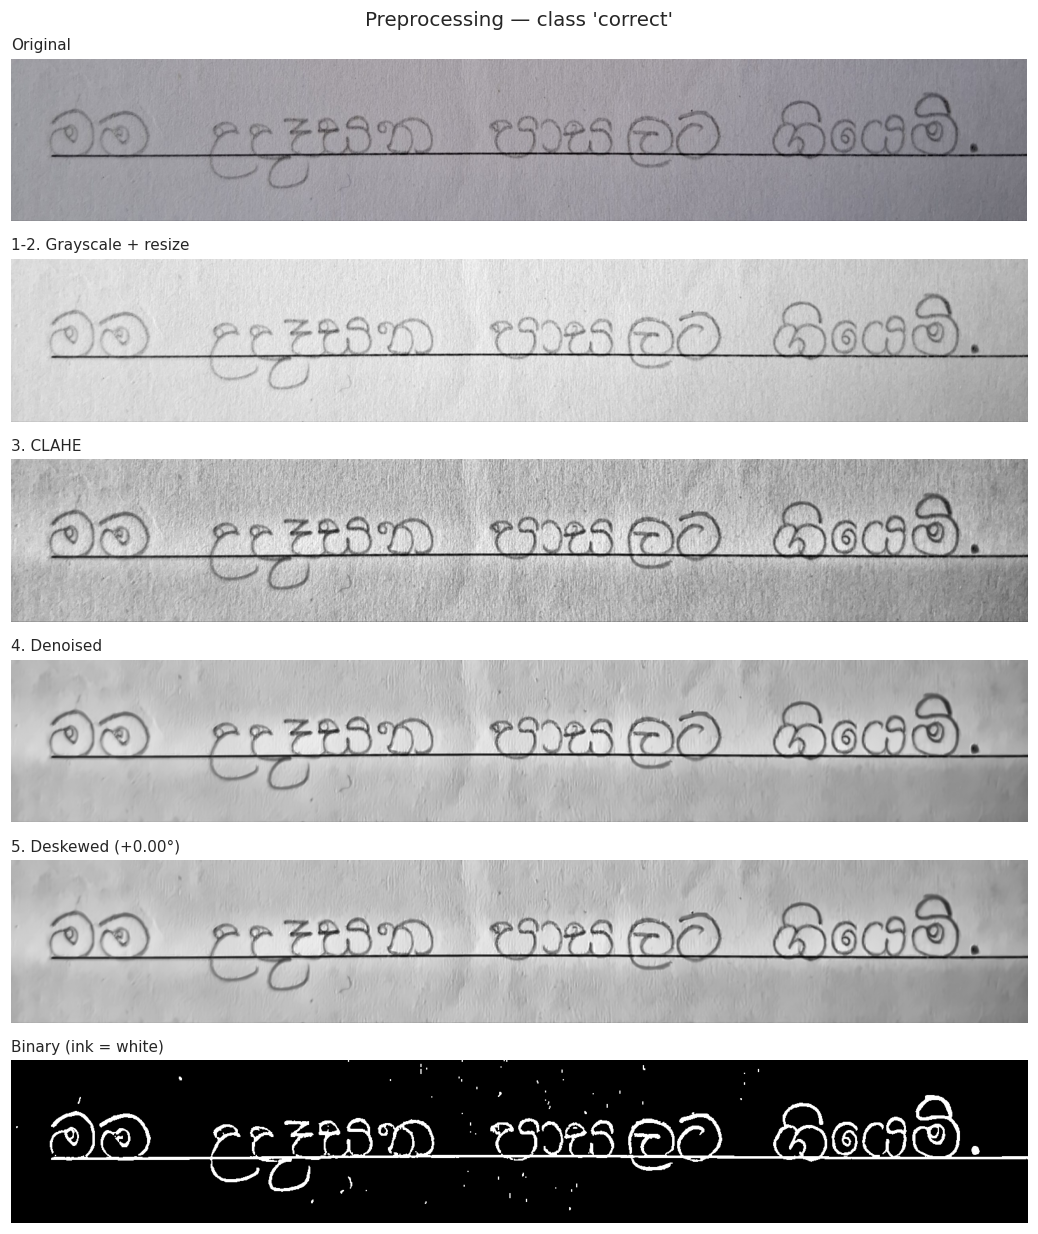

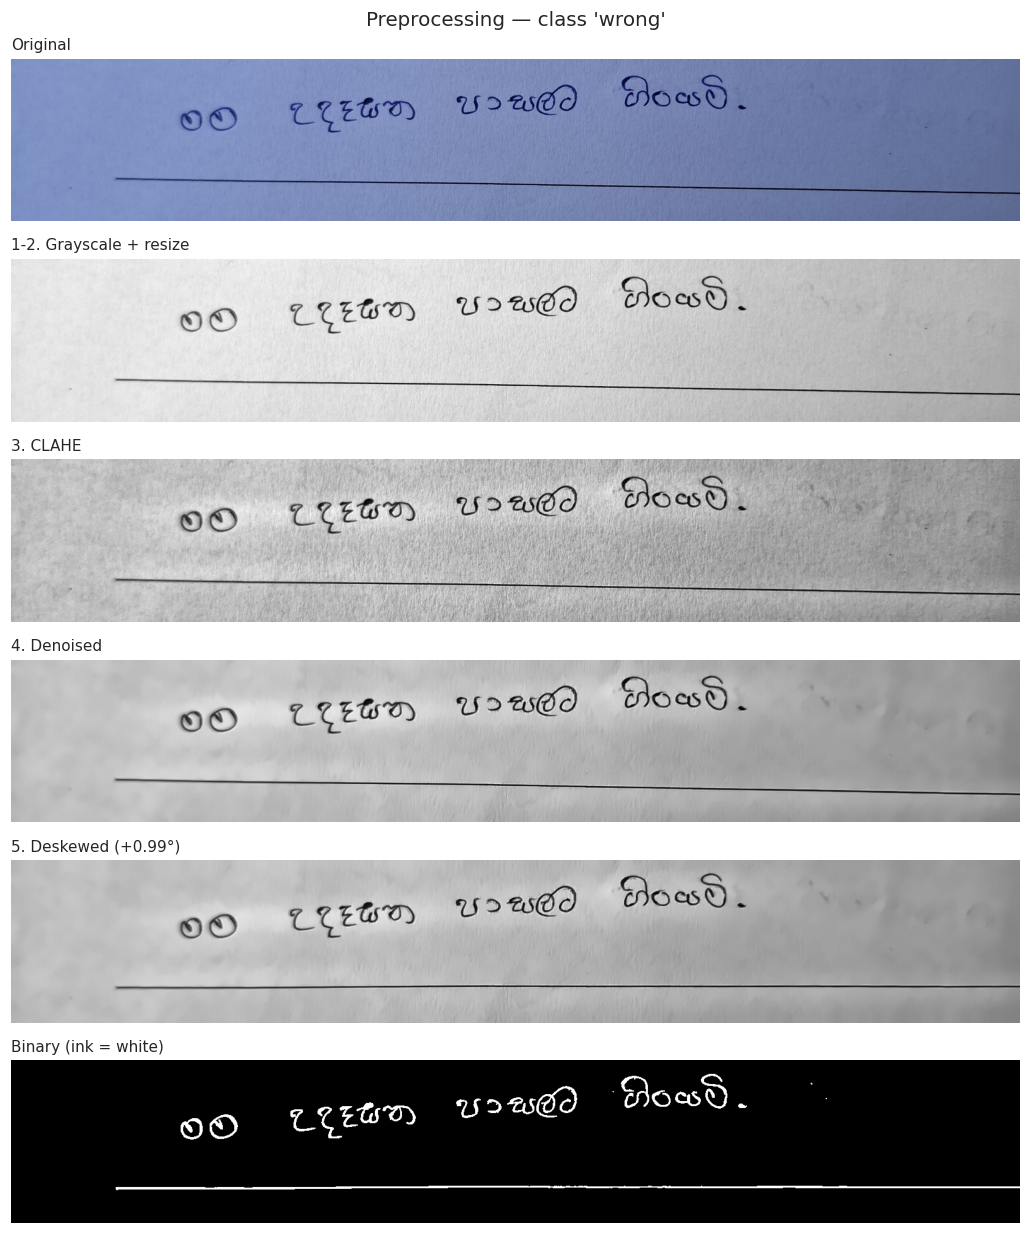

In [ ]:
def binarize(img):
    binary = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 41, 15)
    return cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def guide_line_angle(binary, max_angle=20):
    # angle (degrees) of the longest near-horizontal straight line; 0 if none
    W = binary.shape[1]
    segs = cv2.HoughLinesP(binary, 1, np.pi / 720, threshold=150,
                           minLineLength=int(0.25 * W), maxLineGap=25)
    if segs is None:
        return 0.0
    angles, lengths = [], []
    for x1, y1, x2, y2 in segs.reshape(-1, 4):
        a = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        if abs(a) <= max_angle:
            angles.append(a); lengths.append(np.hypot(x2 - x1, y2 - y1))
    if not angles:
        return 0.0
    order = np.argsort(angles)
    angles, lengths = np.array(angles)[order], np.array(lengths)[order]
    cum = np.cumsum(lengths)
    return float(angles[np.searchsorted(cum, cum[-1] / 2)])        # length-weighted median


def rotate(img, angle):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def preprocess_image(path, target_width=TARGET_WIDTH):
    # returns every intermediate stage; 'final' is the clean grayscale image used for features
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)                  # honours phone EXIF rotation
    if bgr is None:
        raise ValueError(f"Cannot read {path}")
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)                    # 1. grayscale
    h, w = gray.shape
    scale = target_width / w
    gray = cv2.resize(gray, (target_width, max(1, round(h * scale))),  # 2. resize
                      interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)   # 3. lighting
    denoised = cv2.fastNlMeansDenoising(clahe, None, h=10, templateWindowSize=7, searchWindowSize=21)  # 4.
    angle = guide_line_angle(binarize(denoised))                    # 5. deskew (guide line only)
    final = rotate(denoised, angle) if angle != 0.0 else denoised
    return {"original": cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), "gray": gray, "clahe": clahe,
            "denoised": denoised, "final": final, "binary": binarize(final), "skew_angle": angle}


# visualise the pipeline on one image from each class
for cname in CLASS_NAMES:
    p = train_df[train_df.class_name == cname].iloc[0].path
    st = preprocess_image(p)
    stages = [("Original", st["original"]), ("1-2. Grayscale + resize", st["gray"]),
              ("3. CLAHE", st["clahe"]), ("4. Denoised", st["denoised"]),
              (f"5. Deskewed ({st['skew_angle']:+.2f}°)", st["final"]), ("Binary (ink = white)", st["binary"])]
    fig, axes = plt.subplots(len(stages), 1, figsize=(12, 1.9 * len(stages)))
    for ax, (t, im) in zip(axes, stages):
        ax.imshow(im, cmap=None if im.ndim == 3 else "gray"); ax.set_title(t, fontsize=10, loc="left"); ax.axis("off")
    plt.suptitle(f"Preprocessing — class '{cname}'", fontsize=13); plt.tight_layout(); plt.show()

### Preprocess and grayscale **all** images (saved to `/content/work/preprocessed/<split>/<class>/`)

In [ ]:
PRE_DIR = WORK_DIR / "preprocessed"
shutil.rmtree(PRE_DIR, ignore_errors=True)

pre_paths, skews, failed = [], [], []
for _, r in tqdm(df.iterrows(), total=len(df), desc="Preprocessing"):
    out = PRE_DIR / r.split / r.class_name / (Path(r.filename).stem + ".png")
    out.parent.mkdir(parents=True, exist_ok=True)
    try:
        st = preprocess_image(r.path)
        cv2.imwrite(str(out), st["final"])                     # clean grayscale image
        pre_paths.append(str(out)); skews.append(st["skew_angle"])
    except Exception as e:
        pre_paths.append(None); skews.append(np.nan); failed.append((r.filename, str(e)))

df["pre_path"], df["skew_angle"] = pre_paths, skews
if failed:
    print(f"⚠️ {len(failed)} images failed:", failed[:5])
df = df[df.pre_path.notna()].reset_index(drop=True)
print(f"✅ {len(df)} grayscale images saved to {PRE_DIR}")
print(f"Camera tilt corrected: mean |angle| = {df.skew_angle.abs().mean():.2f}°, max = {df.skew_angle.abs().max():.2f}°")

Preprocessing:   0%|          | 0/298 [00:00<?, ?it/s]

✅ 298 grayscale images saved to /content/work/preprocessed
Camera tilt corrected: mean |angle| = 0.57°, max = 2.24°


## Step 6 — Feature extraction with OpenCV

For each preprocessed image:
1. **Detect the printed guide line**: morphological opening with a long horizontal kernel, then a robust line fit (`cv2.fitLine`, Huber).
2. **Remove the guide line** so it does not join letters together.
3. **Group letters into words**: dilation scaled to the character height, then contours.
4. **Robust word bottom** = 85th percentile of the word's ink pixels, so Sinhala descender strokes like **ු / ූ** do not count as deviation.
5. **Gap** = distance from the word bottom to the guide line, divided by character height (positive = above the line). Dividing by character height makes big and small handwriting comparable.

If no printed line is found, a horizontal line through the first word is used as the reference (`line_found = 0`).

| Feature | Meaning |
|---|---|
| `mean_gap`, `median_gap`, `mean_abs_gap` | how far words sit from the line on average |
| `max_gap`, `min_gap`, `max_abs_gap`, `gap_range` | worst deviation above or below |
| `first_gap`, `last_gap`, `first_last_diff` | start vs end of the line |
| `drift_slope` | **rising (+) or falling (−)** trend across the line |
| `waviness`, `mean_step`, `std_gap` | up-and-down wobble between words |
| `frac_floating`, `frac_below`, `frac_on_line` | share of words above / below / on the line |
| `below_ink_ratio` | share of ink cutting below the line |
| `word_height_cv` | letter size consistency |

In [ ]:
FEATURE_NAMES = ["line_found", "n_words", "mean_gap", "median_gap", "std_gap", "max_gap", "min_gap",
                 "max_abs_gap", "mean_abs_gap", "gap_range", "first_gap", "last_gap", "first_last_diff",
                 "drift_slope", "abs_drift_slope", "waviness", "mean_step", "frac_floating", "frac_below",
                 "frac_on_line", "below_ink_ratio", "word_height_cv"]


def line_candidates(binary):
    H, W = binary.shape
    k = max(40, W // 12)
    horiz = cv2.morphologyEx(binary, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (k, 1)))
    horiz = cv2.dilate(horiz, cv2.getStructuringElement(cv2.MORPH_RECT, (31, 3)))   # bridge faint gaps
    n, labels, stats, _ = cv2.connectedComponentsWithStats(horiz)
    cands = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if w < 0.30 * W or h > 0.15 * H:
            continue
        ys, xs = np.where(labels == i)
        vx, vy, x0, y0 = cv2.fitLine(np.column_stack([xs, ys]).astype(np.float32),
                                     cv2.DIST_HUBER, 0, 0.01, 0.01).flatten()
        slope = vy / vx if abs(vx) > 1e-6 else 0.0
        cands.append({"slope": float(slope), "intercept": float(y0 - slope * x0), "label": i})
    return cands, labels


def extract_features(gray, return_debug=False):
    binary = binarize(gray)
    H, W = binary.shape
    cands, line_labels = line_candidates(binary)

    # remove detected guide lines from the ink image
    text_bw = binary.copy()
    if cands:
        line_mask = np.isin(line_labels, [c["label"] for c in cands]).astype(np.uint8) * 255
        line_mask = cv2.dilate(cv2.bitwise_and(line_mask, binary), np.ones((3, 1), np.uint8))
        text_bw = cv2.subtract(text_bw, line_mask)
        text_bw = cv2.morphologyEx(text_bw, cv2.MORPH_CLOSE, np.ones((5, 1), np.uint8))

    # blank a thin border (paper edges / shadows) and drop noise specks
    m = max(4, int(0.01 * min(H, W)))
    text_bw[:m, :] = 0; text_bw[-m:, :] = 0; text_bw[:, :m] = 0; text_bw[:, -m:] = 0
    n, labels, stats, _ = cv2.connectedComponentsWithStats(text_bw)
    keep = np.zeros(n, bool); keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= 25
    text_bw = (keep[labels] * 255).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(text_bw)

    empty = {k: np.nan for k in FEATURE_NAMES}; empty.update(line_found=int(bool(cands)), n_words=0)
    if n <= 1:
        return (empty, None) if return_debug else empty

    # typical character height
    areas, heights = stats[1:, cv2.CC_STAT_AREA], stats[1:, cv2.CC_STAT_HEIGHT]
    big = heights[areas >= np.percentile(areas, 30)]
    char_h = max(8.0, float(np.median(big)) if len(big) else float(np.median(heights)))

    # group letters into words
    kw, kh = max(5, int(0.6 * char_h)) | 1, max(3, int(0.4 * char_h)) | 1
    merged = cv2.dilate(text_bw, cv2.getStructuringElement(cv2.MORPH_RECT, (kw, kh)))
    contours, _ = cv2.findContours(merged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    words = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        ys, xs = np.nonzero(text_bw[y:y + h, x:x + w])
        if len(ys) < 0.15 * char_h * char_h:                   # full stops, dots, noise
            continue
        if w < 0.35 * char_h and h < 0.35 * char_h:
            continue
        if x <= m + 2 or x + w >= W - m - 2:                   # touches the page edge
            continue
        if h > 2.5 * char_h and w < 0.25 * h:                  # margin line / paper fold
            continue
        ys = ys + y
        words.append({"x": x, "y": y, "w": w, "h": h, "cx": x + w / 2.0,
                      "bottom": float(np.percentile(ys, 85)), "ys": ys})
    if not words:
        return (empty, None) if return_debug else empty
    words.sort(key=lambda d: d["cx"])
    bottoms = np.array([wd["bottom"] for wd in words])
    cxs = np.array([wd["cx"] for wd in words])

    # pick the guide line that the text is written on
    line = None
    if cands:
        def score(c):
            d = (c["slope"] * cxs + c["intercept"]) - bottoms
            return np.sum((d > -2 * char_h) & (d < 5 * char_h)) * 1000 - np.mean(np.abs(d))
        line = max(cands, key=score)
    line_y = line["slope"] * cxs + line["intercept"] if line else np.full_like(bottoms, bottoms[0])

    gaps = (line_y - bottoms) / char_h                         # + above line, − below line
    xn = (cxs - cxs.min()) / max(1.0, cxs.max() - cxs.min())   # 0 … 1 along the line
    if len(words) >= 2:
        drift, icpt = np.polyfit(xn, gaps, 1); resid = gaps - (drift * xn + icpt)
    else:
        drift, resid = 0.0, np.zeros(1)
    total_ink = sum(len(wd["ys"]) for wd in words)
    below_ink = sum(int(np.sum(wd["ys"] > ly + 0.25 * char_h)) for wd, ly in zip(words, line_y))
    hs = np.array([wd["h"] for wd in words], float)
    tol = 0.35

    f = {"line_found": int(line is not None), "n_words": len(words),
         "mean_gap": gaps.mean(), "median_gap": np.median(gaps), "std_gap": gaps.std(),
         "max_gap": gaps.max(), "min_gap": gaps.min(), "max_abs_gap": np.abs(gaps).max(),
         "mean_abs_gap": np.abs(gaps).mean(), "gap_range": gaps.max() - gaps.min(),
         "first_gap": gaps[0], "last_gap": gaps[-1], "first_last_diff": gaps[-1] - gaps[0],
         "drift_slope": drift, "abs_drift_slope": abs(drift), "waviness": resid.std(),
         "mean_step": np.abs(np.diff(gaps)).mean() if len(gaps) > 1 else 0.0,
         "frac_floating": np.mean(gaps > tol), "frac_below": np.mean(gaps < -tol),
         "frac_on_line": np.mean(np.abs(gaps) <= tol), "below_ink_ratio": below_ink / max(1, total_ink),
         "word_height_cv": hs.std() / max(1e-6, hs.mean())}
    f = {k: float(v) for k, v in f.items()}
    if not return_debug:
        return f
    return f, {"gray": gray, "words": words, "line": line, "line_y": line_y, "gaps": gaps, "char_h": char_h}


def draw_measurements(dbg):
    vis = cv2.cvtColor(dbg["gray"], cv2.COLOR_GRAY2RGB)
    W = vis.shape[1]
    if dbg["line"] is not None:
        L = dbg["line"]
        cv2.line(vis, (0, int(L["intercept"])), (W, int(L["slope"] * W + L["intercept"])), (0, 190, 0), 3)
    for wd, ly, g in zip(dbg["words"], dbg["line_y"], dbg["gaps"]):
        cv2.rectangle(vis, (wd["x"], wd["y"]), (wd["x"] + wd["w"], wd["y"] + wd["h"]), (30, 90, 255), 2)
        cx, b = int(wd["cx"]), int(wd["bottom"])
        cv2.line(vis, (cx, b), (cx, int(ly)), (230, 0, 0), 3); cv2.circle(vis, (cx, b), 6, (230, 0, 0), -1)
        cv2.putText(vis, f"{g:+.2f}", (wd["x"], max(22, wd["y"] - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (230, 0, 0), 2)
    return vis

### Check what OpenCV measures (green = guide line, blue = words, red = gap in character heights)

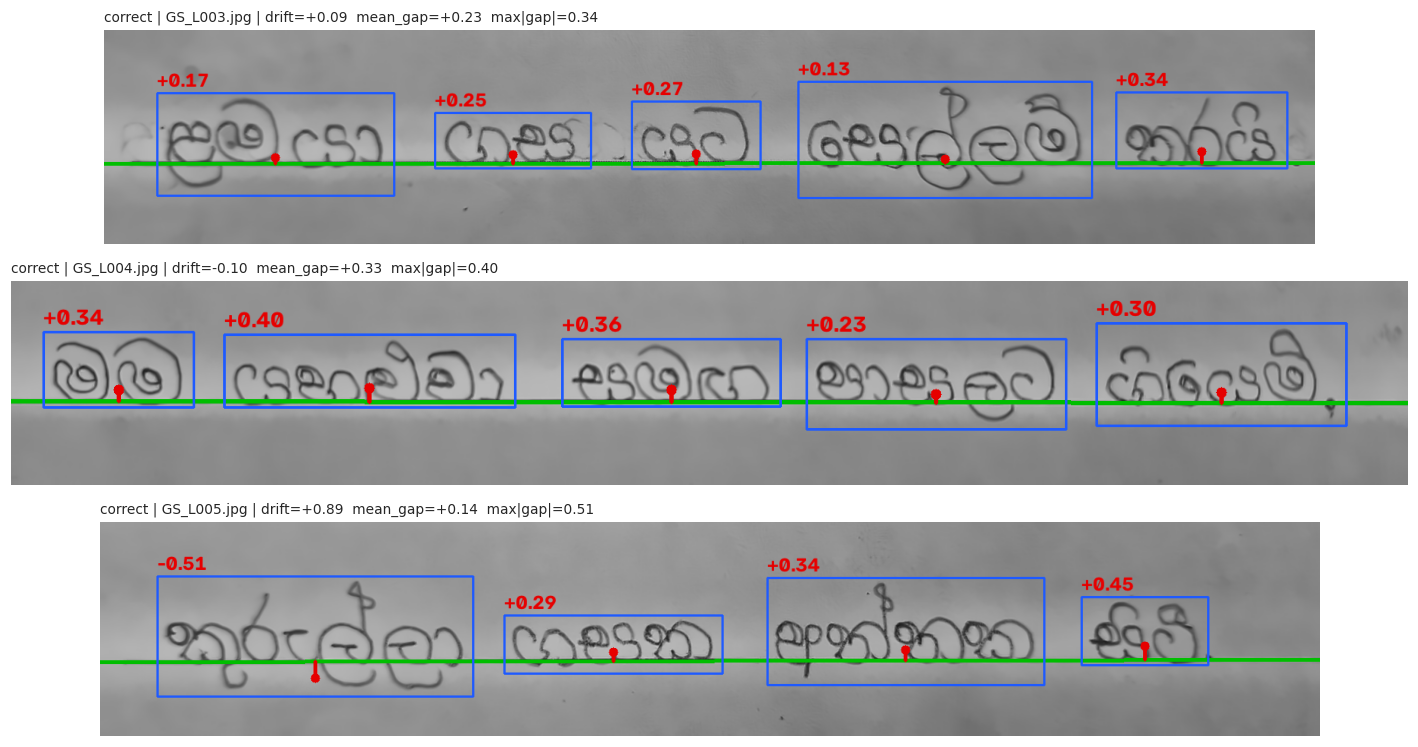

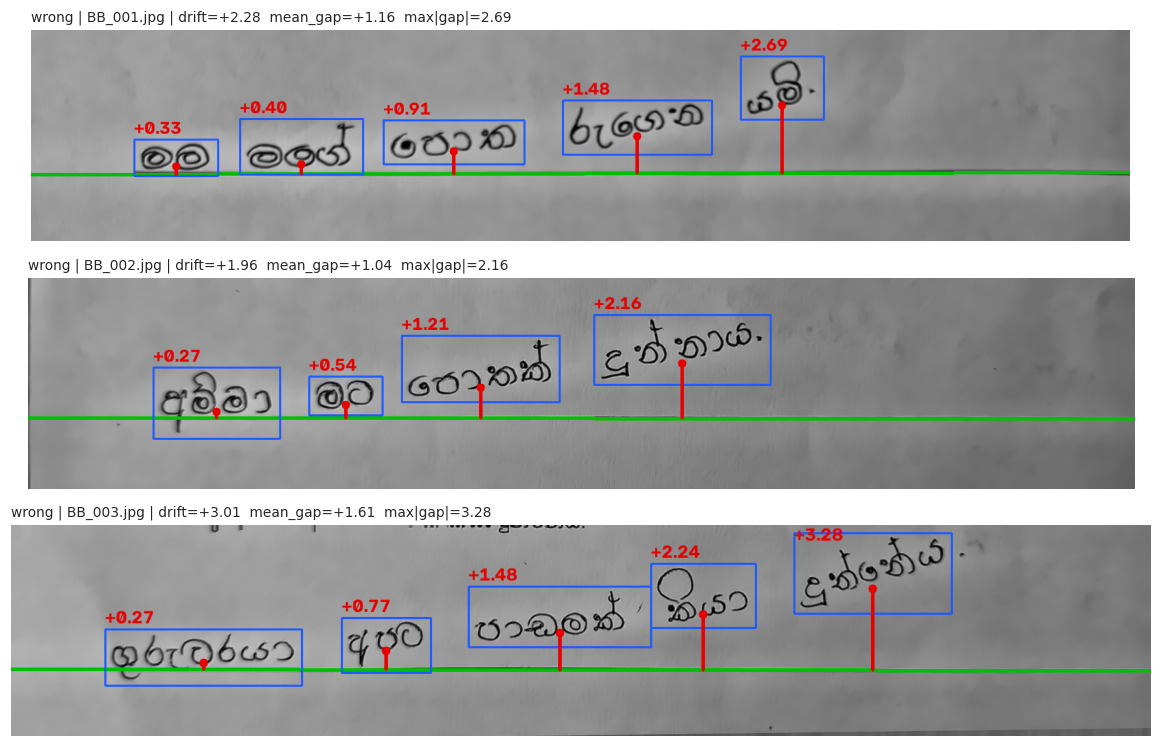

In [ ]:
n_show = 3
for cname in CLASS_NAMES:
    sub = df[(df.split == "train") & (df.class_name == cname)].head(n_show)
    fig, axes = plt.subplots(len(sub), 1, figsize=(13, 2.3 * len(sub)), squeeze=False)
    for ax, (_, r) in zip(axes[:, 0], sub.iterrows()):
        f, dbg = extract_features(cv2.imread(r.pre_path, cv2.IMREAD_GRAYSCALE), return_debug=True)
        ax.imshow(draw_measurements(dbg) if dbg else cv2.imread(r.pre_path), cmap="gray"); ax.axis("off")
        ax.set_title(f"{cname} | {r.filename} | drift={f['drift_slope']:+.2f}  mean_gap={f['mean_gap']:+.2f}  "
                     f"max|gap|={f['max_abs_gap']:.2f}", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

### Extract features for all images

In [ ]:
rows = []
for _, r in tqdm(df.iterrows(), total=len(df), desc="Extracting features"):
    f = extract_features(cv2.imread(r.pre_path, cv2.IMREAD_GRAYSCALE))
    rows.append({**f, "filename": r.filename, "path": r.path, "pre_path": r.pre_path,
                 "label": r.label, "class_name": r.class_name, "split": r.split})
feat_df = pd.DataFrame(rows)
feat_df.to_csv(WORK_DIR / "features.csv", index=False)

print("Guide line found in", f"{100 * feat_df.line_found.mean():.1f}% of images")
print("Images where no words were found:", int((feat_df.n_words == 0).sum()))
display(feat_df[FEATURE_NAMES + ["class_name", "split"]].head())

X_train = feat_df.loc[feat_df.split == "train", FEATURE_NAMES].values
y_train = feat_df.loc[feat_df.split == "train", "label"].values
X_val   = feat_df.loc[feat_df.split == "val",   FEATURE_NAMES].values
y_val   = feat_df.loc[feat_df.split == "val",   "label"].values
X_test  = feat_df.loc[feat_df.split == "test",  FEATURE_NAMES].values
y_test  = feat_df.loc[feat_df.split == "test",  "label"].values
print(f"\nX_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")

Extracting features:   0%|          | 0/298 [00:00<?, ?it/s]

Guide line found in 100.0% of images
Images where no words were found: 0


,line_found,n_words,mean_gap,median_gap,std_gap,max_gap,min_gap,max_abs_gap,mean_abs_gap,gap_range,...,abs_drift_slope,waviness,mean_step,frac_floating,frac_below,frac_on_line,below_ink_ratio,word_height_cv,class_name,split
0,1.0,5.0,0.302497,0.274090,0.046515,0.380549,0.258772,0.380549,0.302497,0.121777,...,0.107812,0.025902,0.035797,0.20,0.00,0.8,0.000000,0.134629,correct,val
1,1.0,5.0,0.246372,0.318444,0.103182,0.342500,0.118045,0.342500,0.246372,0.224454,...,0.257210,0.041235,0.057269,0.00,0.00,1.0,0.027161,0.215771,correct,test
2,1.0,5.0,0.231844,0.253387,0.075020,0.336016,0.126078,0.336016,0.231844,0.209937,...,0.085819,0.068768,0.115544,0.00,0.00,1.0,0.059330,0.269189,correct,train
3,1.0,5.0,0.326399,0.340964,0.056622,0.397867,0.230838,0.397867,0.326399,0.167029,...,0.096860,0.044939,0.074143,0.40,0.00,0.6,0.014855,0.157751,correct,train
4,1.0,4.0,0.144176,0.316068,0.380720,0.451857,-0.507287,0.507287,0.397820,0.959144,...,0.890798,0.182160,0.319715,0.25,0.25,0.5,0.073347,0.293128,correct,train



X_train (208, 22) | X_val (45, 22) | X_test (45, 22)


### Feature exploration (training data only)

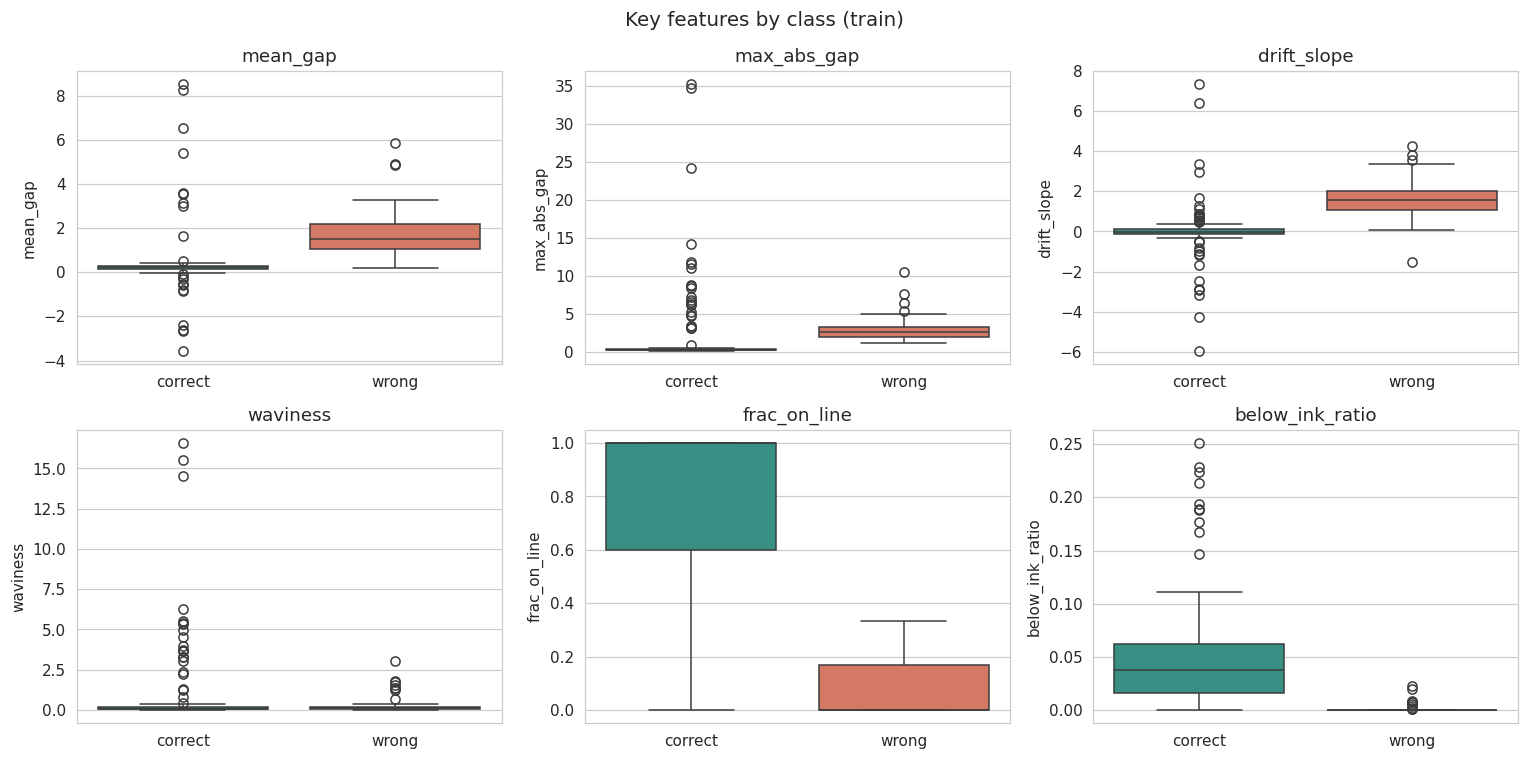

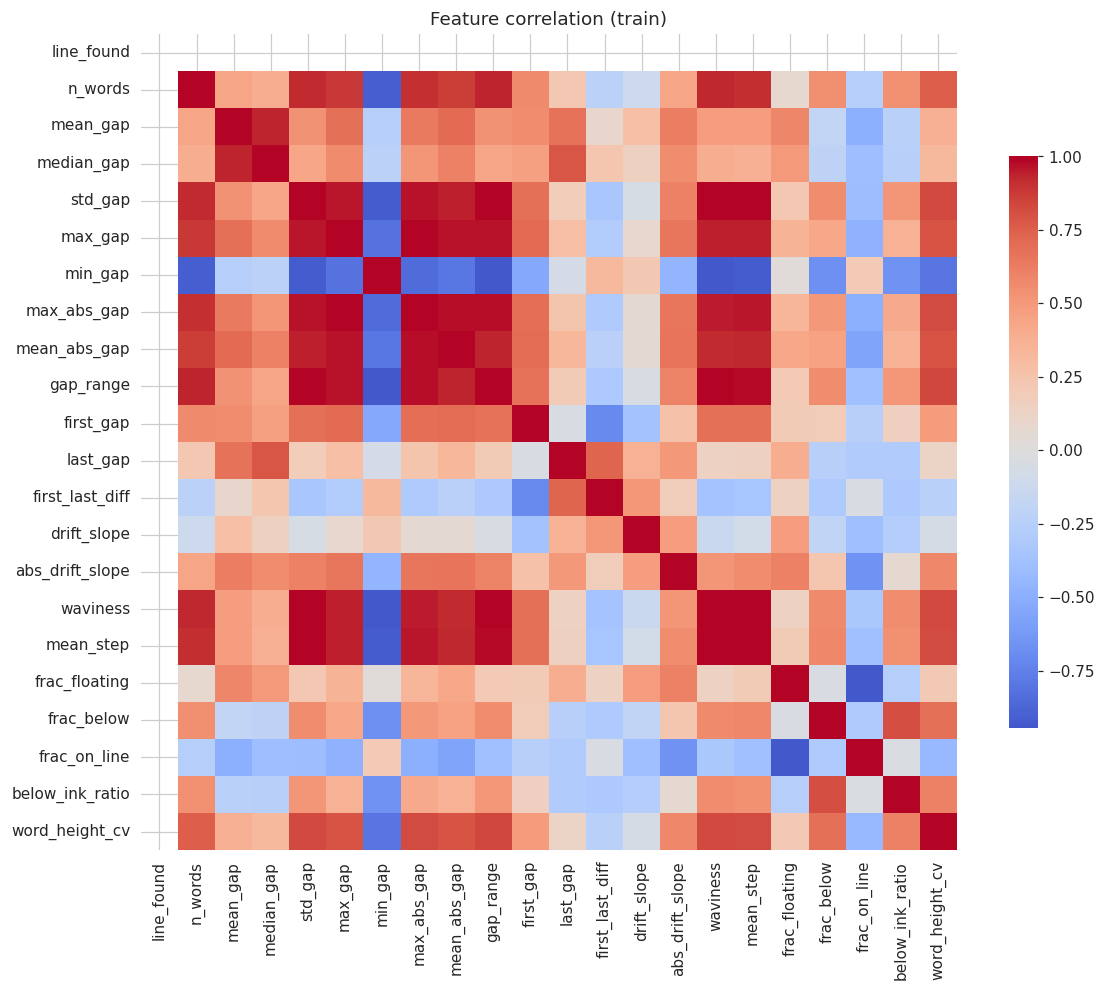

In [ ]:
tr = feat_df[feat_df.split == "train"]
key = ["mean_gap", "max_abs_gap", "drift_slope", "waviness", "frac_on_line", "below_ink_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, k in zip(axes.ravel(), key):
    sns.boxplot(data=tr, x="class_name", y=k, order=CLASS_NAMES, palette=["#2a9d8f", "#e76f51"], ax=ax)
    ax.set_title(k); ax.set_xlabel("")
plt.suptitle("Key features by class (train)", fontsize=13); plt.tight_layout(); plt.show()

plt.figure(figsize=(11, 9))
sns.heatmap(tr[FEATURE_NAMES].corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation (train)"); plt.tight_layout(); plt.show()

## Step 7 — Training & evaluation functions

The procedure:
1. **Hyperparameter tuning** with stratified k-fold cross-validation on the **training set only** (scoring = F1 for the *wrong* class)
2. Evaluation on **train / validation / test**
3. Classification report, confusion matrix, ROC and Precision–Recall curves
4. Cross-validation stability and learning curve
5. The trained model is **saved as its own file**

`class_weight="balanced"` handles the class imbalance.

In [ ]:
n_pos, n_neg = int((y_train == 1).sum()), int((y_train == 0).sum())
cv_folds = max(2, min(5, n_pos, n_neg))
CV = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=SEED)
X_trval, y_trval = np.vstack([X_train, X_val]), np.concatenate([y_train, y_val])
MODELS_DIR = WORK_DIR / "models"; MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Train: {n_neg} correct / {n_pos} wrong  →  {cv_folds}-fold cross-validation")


def make_pipe(clf, scale=True):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps + [("clf", clf)])


def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall / Sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob) if both else np.nan,
        "PR-AUC (Avg Precision)": average_precision_score(y_true, y_prob) if both else np.nan,
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Log Loss": log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7), labels=[0, 1]),
        "Brier Score": brier_score_loss(y_true, y_prob),
        "False Positive Rate": fp / (fp + tn) if (fp + tn) else np.nan,
        "False Negative Rate": fn / (fn + tp) if (fn + tp) else np.nan,
        "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
    }


def evaluate(model, X, y):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return compute_metrics(y, pred, prob), pred, prob


RESULTS = {}     # filled by each experiment, used in the comparison step


def run_experiment(exp_name, clf, grid, scale=True, color="#457b9d"):
    print("=" * 78); print(f"  EXPERIMENT: {exp_name}"); print("=" * 78)

    # 1. tune + train on the training set
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf, scale), grid, scoring="f1", cv=CV, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    model, train_time = gs.best_estimator_, time.time() - t0
    best_params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    print(f"Best hyperparameters : {best_params}")
    print(f"CV F1 (training set) : {gs.best_score_:.4f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.4f}")
    print(f"Training time        : {train_time:.1f} s")

    # 2. evaluate on every split
    split_metrics, outputs = {}, {}
    for s, X, y in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
        split_metrics[s], pred, prob = evaluate(model, X, y)
        outputs[s] = (pred, prob)
    tm = split_metrics["Test"]; test_pred, test_prob = outputs["Test"]
    print(f"\n   ✅ TEST ACCURACY : {tm['Accuracy'] * 100:.2f}%")
    print(f"   ✅ TEST F1-SCORE : {tm['F1-score']:.4f}")
    print(f"   ✅ TEST RECALL   : {tm['Recall / Sensitivity']:.4f}")
    print(f"   ✅ TEST MCC      : {tm['MCC']:.4f}\n")
    metrics_table = pd.DataFrame(split_metrics)
    display(metrics_table.style.format(lambda v: f"{v:.4f}" if isinstance(v, float) else v)
            .set_caption(f"{exp_name} — all evaluation metrics"))

    # 3. classification report
    print(f"Classification report — {exp_name} (test set)\n")
    print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

    # 4. confusion matrix, ROC, PR
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=axes[0], annot_kws={"size": 13})
    axes[0].set(xlabel="Predicted", ylabel="Actual", title="Confusion matrix (test)")
    if len(np.unique(y_test)) == 2:
        fpr, tpr, _ = roc_curve(y_test, test_prob)
        axes[1].plot(fpr, tpr, lw=2.5, color=color, label=f"AUC = {tm['ROC-AUC']:.4f}")
        prec, rec, _ = precision_recall_curve(y_test, test_prob)
        axes[2].plot(rec, prec, lw=2.5, color=color, label=f"AP = {tm['PR-AUC (Avg Precision)']:.4f}")
        axes[2].axhline(y_test.mean(), ls="--", color="gray", label=f"Baseline = {y_test.mean():.2f}")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC curve (test)")
    axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curve (test)")
    axes[1].legend(); axes[2].legend()
    plt.suptitle(exp_name, fontsize=14); plt.tight_layout(); plt.show()

    # 5. cross-validation stability (train + validation) and learning curve
    k = max(2, min(10, int((y_trval == 1).sum()), int((y_trval == 0).sum())))
    cvr = cross_validate(model, X_trval, y_trval, cv=StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED),
                         scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"])
    cv_summary = pd.DataFrame({m.replace("test_", ""): [cvr[m].mean(), cvr[m].std()]
                               for m in cvr if m.startswith("test_")}, index=["mean", "std"]).T
    sizes, tr_sc, va_sc = learning_curve(model, X_trval, y_trval, scoring="f1", n_jobs=-1,
                                         cv=StratifiedKFold(n_splits=min(5, k), shuffle=True, random_state=SEED),
                                         train_sizes=np.linspace(0.2, 1.0, 6), random_state=SEED, shuffle=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    cv_summary["mean"].plot.bar(yerr=cv_summary["std"], capsize=4, rot=30, color=color, ax=axes[0])
    axes[0].set_ylim(0, 1.05); axes[0].set_title(f"{k}-fold cross-validation (mean ± std)")
    for sc, lbl, c in [(tr_sc, "Training", "#e76f51"), (va_sc, "Cross-validation", "#2a9d8f")]:
        axes[1].plot(sizes, sc.mean(1), "o-", color=c, label=lbl)
        axes[1].fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=.15, color=c)
    axes[1].set(xlabel="Training samples", ylabel="F1-score", ylim=(0, 1.05), title="Learning curve")
    axes[1].legend(); plt.suptitle(exp_name, fontsize=14); plt.tight_layout(); plt.show()
    display(cv_summary.style.format("{:.4f}").set_caption(f"{exp_name} — {k}-fold cross-validation"))

    # 6. save this experiment's model as its own file
    slug = re.sub(r"[^a-z0-9]+", "_", exp_name.lower()).strip("_")
    model_path = MODELS_DIR / f"{slug}.joblib"
    joblib.dump({"model": model, "model_name": exp_name, "feature_names": FEATURE_NAMES,
                 "class_names": CLASS_NAMES, "threshold": 0.5, "target_width": TARGET_WIDTH,
                 "best_params": best_params}, model_path)
    metrics_table.to_csv(MODELS_DIR / f"{slug}_metrics.csv")
    print(f"\n💾 Model saved: {model_path}")

    RESULTS[exp_name] = {"model": model, "metrics": split_metrics, "test_pred": test_pred, "test_prob": test_prob,
                         "best_params": best_params, "cv_f1": gs.best_score_, "train_time": train_time,
                         "cv_summary": cv_summary, "color": color, "path": model_path}
    return model

Train: 143 correct / 65 wrong  →  5-fold cross-validation


## Step 8 — Train & evaluate: OpenCV + Decision Tree

A Decision Tree learns **if/else rules** on the OpenCV measurements. Trees do not need feature scaling, so the thresholds below are in **real units** (character heights), which makes the model easy to explain.

  EXPERIMENT: OpenCV + Decision Tree
Best hyperparameters : {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 4}
CV F1 (training set) : 0.9772 ± 0.0306
Training time        : 4.5 s

   ✅ TEST ACCURACY : 95.56%
   ✅ TEST F1-SCORE : 0.9286
   ✅ TEST RECALL   : 0.9286
   ✅ TEST MCC      : 0.8963



,Train,Validation,Test
Accuracy,0.9904,1.0000,0.9556
Balanced Accuracy,0.9930,1.0000,0.9482
Precision,0.9701,1.0000,0.9286
Recall / Sensitivity,1.0000,1.0000,0.9286
Specificity,0.9860,1.0000,0.9677
NPV,1.0000,1.0000,0.9677
F1-score,0.9848,1.0000,0.9286
F1 (macro),0.9889,1.0000,0.9482
F1 (weighted),0.9904,1.0000,0.9556
ROC-AUC,0.9930,1.0000,0.9482


Classification report — OpenCV + Decision Tree (test set)

              precision    recall  f1-score   support

     correct     0.9677    0.9677    0.9677        31
       wrong     0.9286    0.9286    0.9286        14

    accuracy                         0.9556        45
   macro avg     0.9482    0.9482    0.9482        45
weighted avg     0.9556    0.9556    0.9556        45



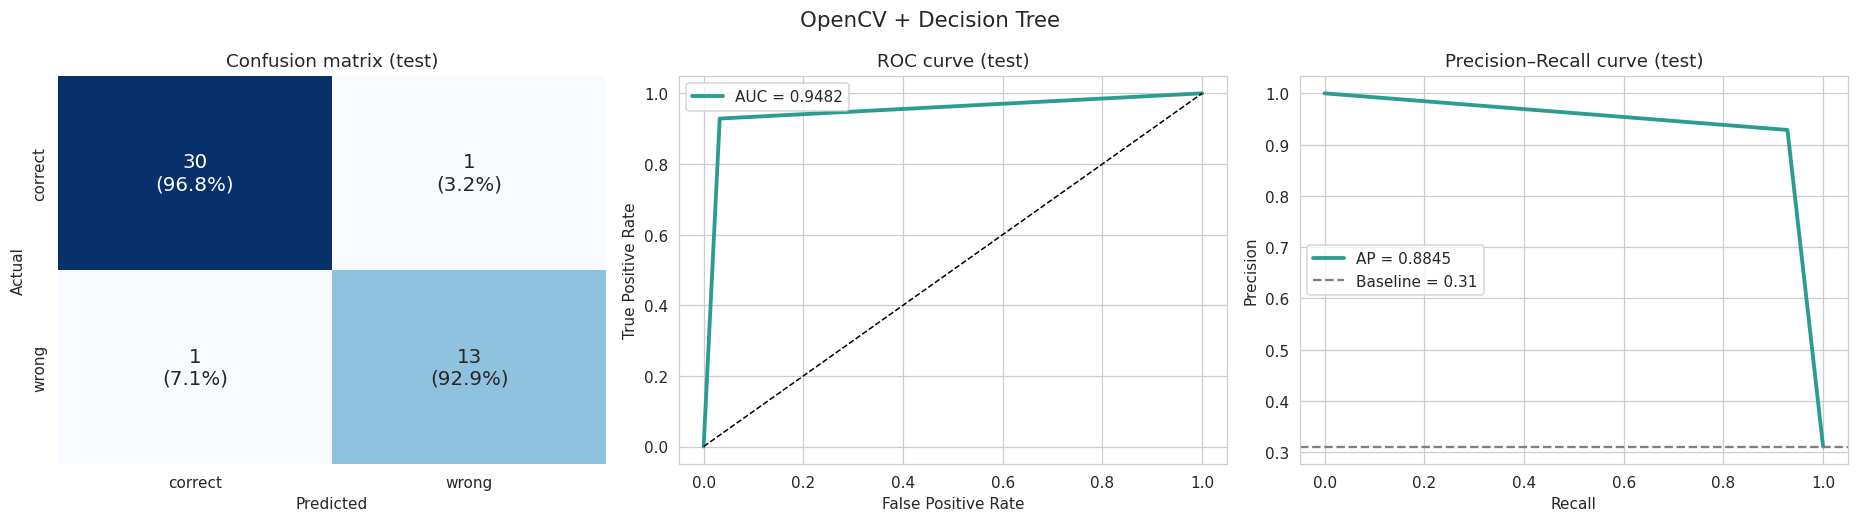

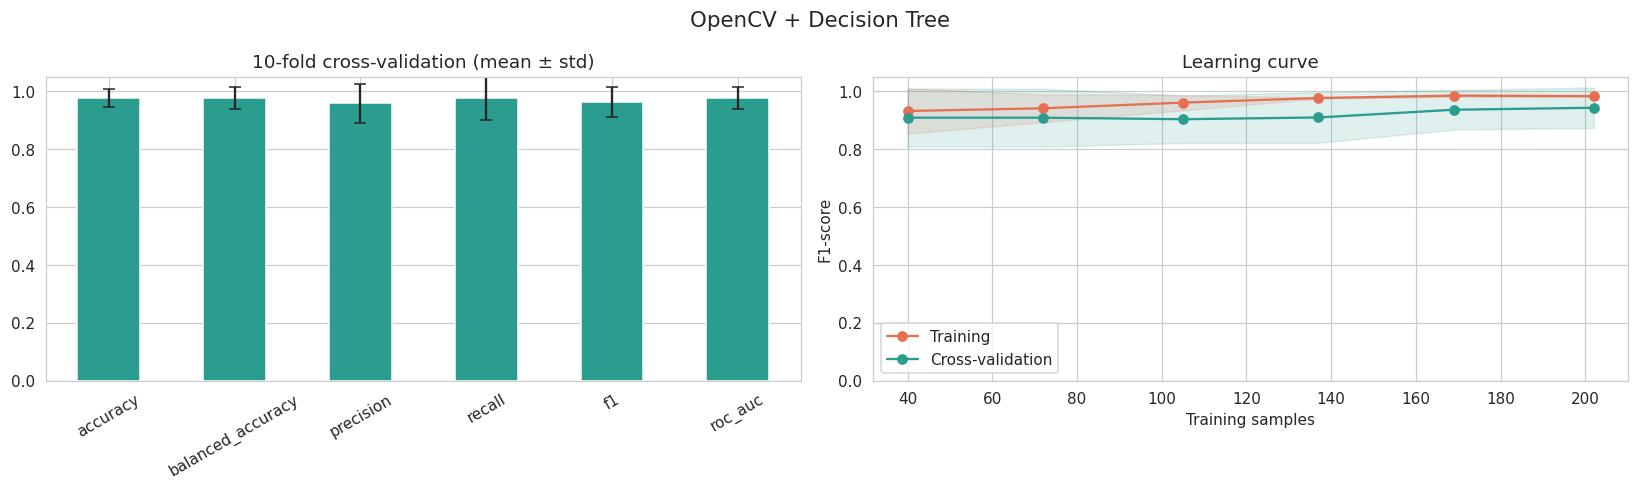

,mean,std
accuracy,0.9760,0.0320
balanced_accuracy,0.9757,0.0386
precision,0.9578,0.0685
recall,0.9750,0.0750
f1,0.9628,0.0509
roc_auc,0.9757,0.0386



💾 Model saved: /content/work/models/opencv_decision_tree.joblib


In [ ]:
DT_NAME = "OpenCV + Decision Tree"
dt_model = run_experiment(
    DT_NAME,
    DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    {"clf__max_depth": [2, 3, 4, 5, 6, 8, None],
     "clf__min_samples_leaf": [1, 2, 4, 6],
     "clf__criterion": ["gini", "entropy"]},
    scale=False, color="#2a9d8f")

### Decision Tree rules (in real OpenCV measurement units)

Depth = 2, leaves = 4

|--- frac_floating <= 0.662
|   |--- mean_step <= 0.029
|   |   |--- weights: [2.909, 0.000] → CORRECT
|   |--- mean_step >  0.029
|   |   |--- weights: [96.000, 0.000] → CORRECT
|--- frac_floating >  0.662
|   |--- below_ink_ratio <= 0.024
|   |   |--- weights: [1.455, 104.000] → WRONG
|   |--- below_ink_ratio >  0.024
|   |   |--- weights: [3.636, 0.000] → CORRECT



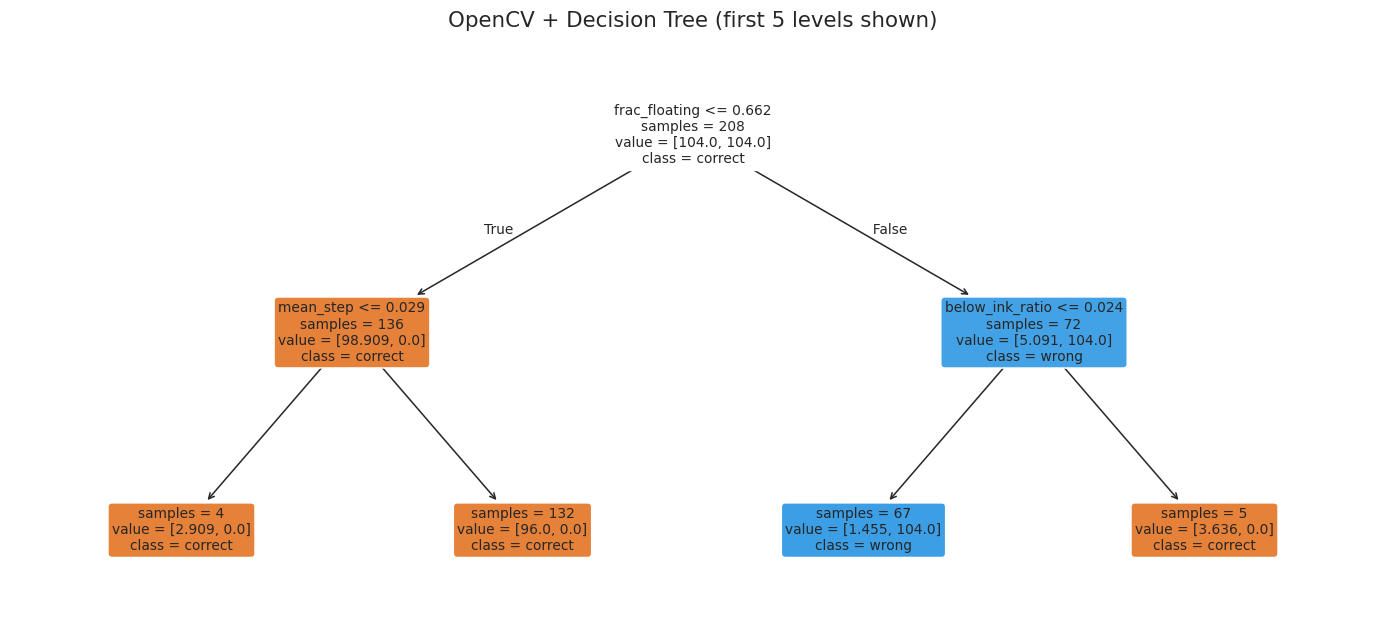

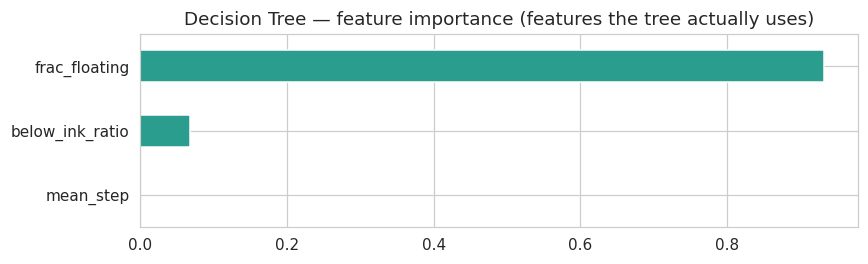

In [ ]:
from sklearn.tree import export_text, plot_tree
dt_clf = dt_model.named_steps["clf"]
print(f"Depth = {dt_clf.get_depth()}, leaves = {dt_clf.get_n_leaves()}\n")
print(export_text(dt_clf, feature_names=FEATURE_NAMES, decimals=3, show_weights=True)
      .replace("class: 0", "→ CORRECT").replace("class: 1", "→ WRONG"))

plt.figure(figsize=(min(26, 4 + 3 * dt_clf.get_n_leaves()), 3 + 2 * dt_clf.get_depth()))
plot_tree(dt_clf, feature_names=FEATURE_NAMES, class_names=CLASS_NAMES, filled=True, rounded=True,
          impurity=False, proportion=False, fontsize=9, max_depth=5)
plt.title(f"{DT_NAME} (first 5 levels shown)", fontsize=14); plt.show()

imp = pd.Series(dt_clf.feature_importances_, index=FEATURE_NAMES).sort_values()
imp = imp[imp > 0]
imp.plot.barh(figsize=(8, max(2.5, 0.4 * len(imp))), color="#2a9d8f")
plt.title("Decision Tree — feature importance (features the tree actually uses)"); plt.tight_layout(); plt.show()

## Step 9 — Save and download the model and all results

In [ ]:
res = RESULTS[DT_NAME]
pd.DataFrame(res["metrics"]).to_csv(WORK_DIR / "decision_tree_metrics.csv")
with open(WORK_DIR / "decision_tree_rules.txt", "w", encoding="utf-8") as fh:
    fh.write(export_text(dt_clf, feature_names=FEATURE_NAMES, decimals=3))
with open(WORK_DIR / "summary.json", "w") as fh:
    json.dump({"experiment": DT_NAME,
               "test_metrics": {k: float(v) for k, v in res["metrics"]["Test"].items()},
               "best_params": {k: str(v) for k, v in res["best_params"].items()},
               "tree_depth": int(dt_clf.get_depth()), "tree_leaves": int(dt_clf.get_n_leaves()),
               "model_file": res["path"].name,
               "n_train": len(y_train), "n_val": len(y_val), "n_test": len(y_test)}, fh, indent=2)

results_dir = Path("/content/opencv_decision_tree_results")
shutil.rmtree(results_dir, ignore_errors=True)
shutil.copytree(MODELS_DIR, results_dir / "models")
for p in WORK_DIR.glob("*.*"):
    shutil.copy(p, results_dir / p.name)
shutil.make_archive("/content/opencv_decision_tree_results", "zip", results_dir)
shutil.make_archive("/content/preprocessed_dataset", "zip", WORK_DIR / "preprocessed")

print("Contents of opencv_decision_tree_results.zip:")
for p in sorted(results_dir.rglob("*.*")): print("  ", p.relative_to(results_dir))

if DATA_SOURCE == "drive":
    dst = Path(SAVE_TO_DRIVE_DIR); dst.mkdir(parents=True, exist_ok=True)
    shutil.copy("/content/opencv_decision_tree_results.zip", dst)
    shutil.copy("/content/preprocessed_dataset.zip", dst)
    print("\n📁 Copied to Google Drive:", dst)

try:
    from google.colab import files
    files.download("/content/opencv_decision_tree_results.zip")
    files.download("/content/preprocessed_dataset.zip")
except ImportError:
    pass

Contents of opencv_decision_tree_results.zip:
   dataset_split.csv
   decision_tree_metrics.csv
   decision_tree_rules.txt
   features.csv
   models/opencv_decision_tree.joblib
   models/opencv_decision_tree_metrics.csv
   summary.json

📁 Copied to Google Drive: /content/drive/MyDrive/baseline_DT_results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10 — Predict a new handwriting image

Saving photo_2026-10-24_16-54-40.jpg to photo_2026-10-24_16-54-40.jpg


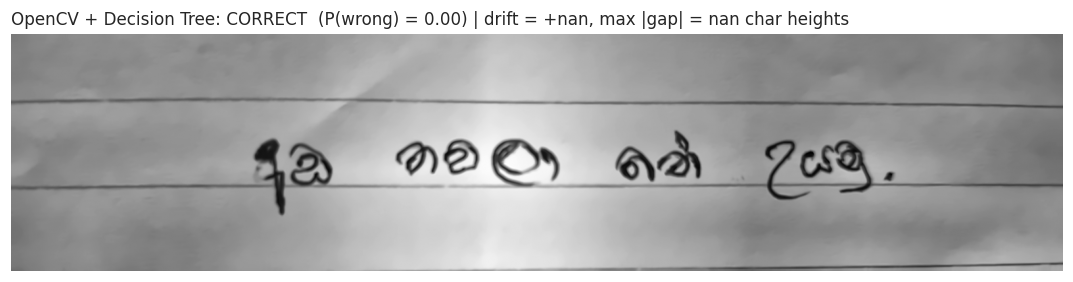

In [ ]:
def predict_image(path, model=dt_model):
    st = preprocess_image(path)
    f, dbg = extract_features(st["final"], return_debug=True)
    x = np.array([[f[k] for k in FEATURE_NAMES]])
    p_wrong = float(model.predict_proba(x)[0, 1])
    label = CLASS_NAMES[int(p_wrong >= 0.5)]
    plt.figure(figsize=(13, 2.8))
    plt.imshow(draw_measurements(dbg) if dbg else st["final"], cmap="gray"); plt.axis("off")
    plt.title(f"{DT_NAME}: {label.upper()}  (P(wrong) = {p_wrong:.2f}) | drift = {f['drift_slope']:+.2f}, "
              f"max |gap| = {f['max_abs_gap']:.2f} char heights", fontsize=11, loc="left")
    plt.show()
    return label, p_wrong


try:
    from google.colab import files
    for name in files.upload():                     # choose one or more images
        predict_image(name)
except ImportError:
    predict_image(feat_df[feat_df.split == "test"].iloc[0].path)